In [5]:
from pathlib import Path
from PIL import Image, ImageStat
from collections import Counter
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys 
from collections import Counter

sys.path.append("../src")
from data import TrainDataset, TestDataset

In [7]:
train_url = Path("../data/Training")
test_url = Path("../data/Testing")

train_dataset = TrainDataset(root=train_url, transform=None)
test_dataset = TestDataset(root=test_url, transform=None)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 5600
Testing images: 1600


In [22]:
label_mapping = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

class_names = list(label_mapping.keys())

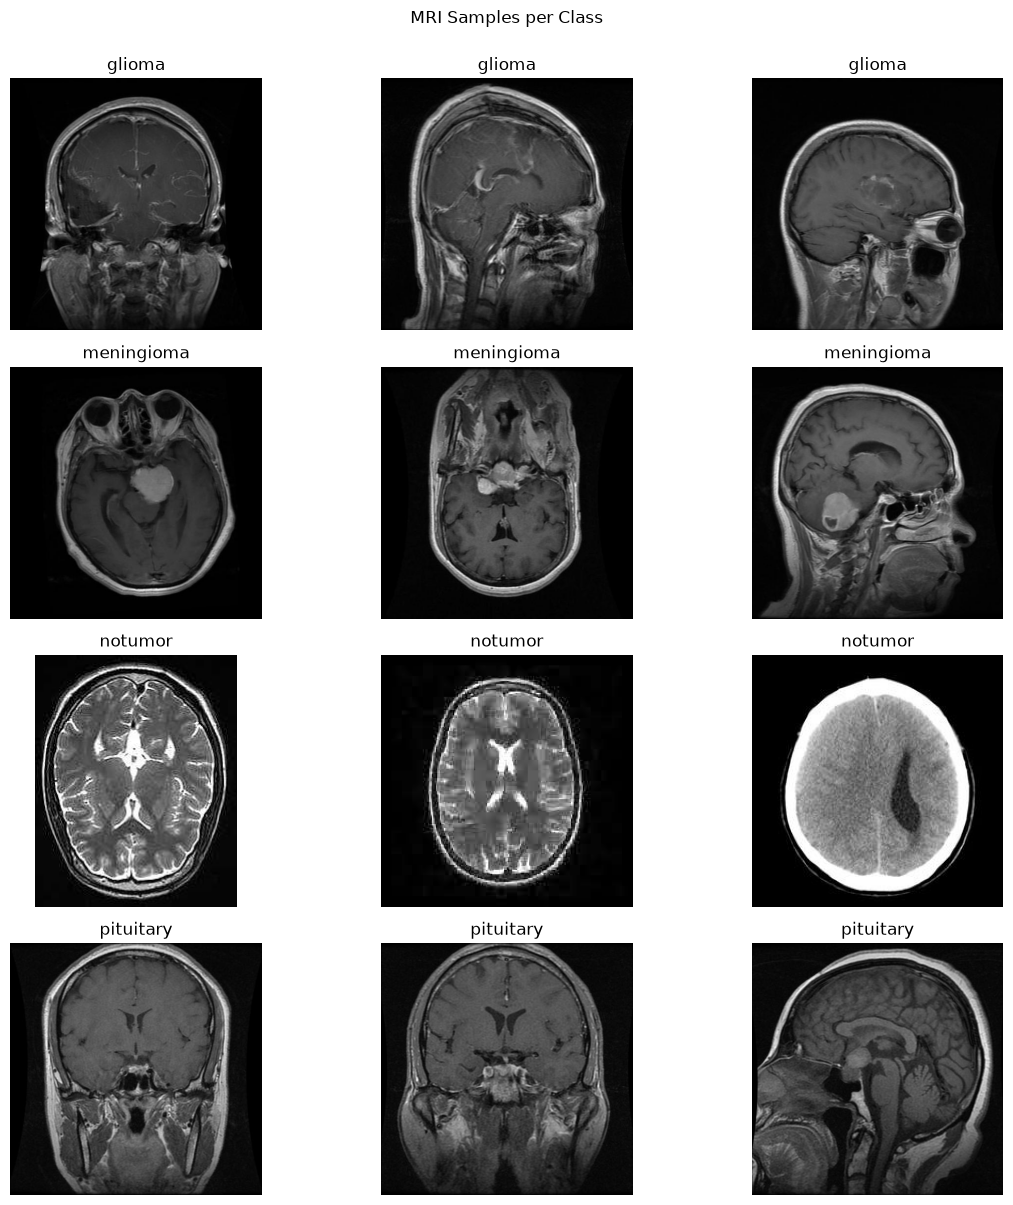

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(12, 12))
for class_name, label in label_mapping.items():
    indices = [
        i for i, y in enumerate(train_dataset.image_labels) if y == label][:3]
    for col in range(3):
        ax = axes[label, col]
        if col < len(indices):
            image, _ = train_dataset[indices[col]]
            ax.imshow(image.convert("RGB"))
            ax.set_title(class_name)
        ax.axis("off")

plt.suptitle("MRI Samples per Class", y=1)
plt.tight_layout()
plt.show()

,class,Training,Testing
0,glioma,1400,400
1,meningioma,1400,400
2,notumor,1400,400
3,pituitary,1400,400


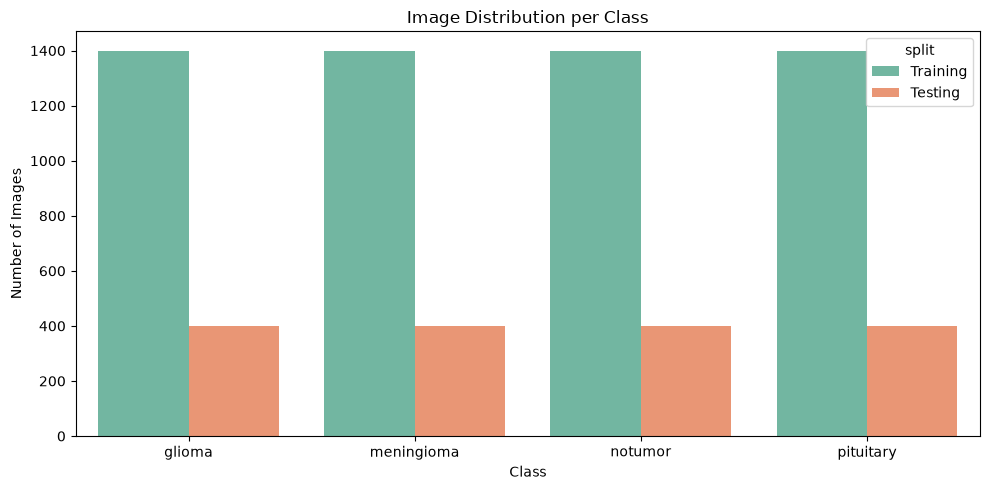

In [24]:
train_counts = Counter(train_dataset.image_labels)
test_counts = Counter(test_dataset.image_labels)

distribution = pd.DataFrame({
    "class": class_names,
    "Training": [train_counts[label_mapping[c]] for c in class_names],
    "Testing": [test_counts[label_mapping[c]] for c in class_names]
})
display(distribution)

distribution_long = distribution.melt(id_vars="class", var_name="split", value_name="count")

plt.figure(figsize=(10, 5))
sns.barplot(data=distribution_long, x="class", y="count", hue="split", palette="Set2")
plt.title("Image Distribution per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()



In [26]:
records = []

for split, dataset in [("Training", train_dataset), ("Testing", test_dataset)]:
    for path, label in zip(dataset.image, dataset.image_labels):
        path = Path(path)

        try:
            with Image.open(path) as img:
                gray = img.convert("L")
                stats = ImageStat.Stat(gray)

                records.append({
                    "split": split,
                    "class": next(
                        name for name, value in label_mapping.items()
                        if value == label
                    ),
                    "path": str(path),
                    "width": img.width,
                    "height": img.height,
                    "aspect_ratio": img.width / img.height,
                    "format": img.format,
                    "brightness": stats.mean[0],
                    "contrast": stats.stddev[0]
                })
                gray.close()

        except Exception as e:
            print(f"Invalid image: {path} | {e}")

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7200, 9)


,split,class,path,width,height,aspect_ratio,format,brightness,contrast
0,Training,glioma,..\data\Training\glioma\Tr-gl_1.jpg,512,512,1.0,JPEG,34.543823,36.679668
1,Training,glioma,..\data\Training\glioma\Tr-gl_10.jpg,512,512,1.0,JPEG,48.690544,44.468923
2,Training,glioma,..\data\Training\glioma\Tr-gl_100.jpg,512,512,1.0,JPEG,43.763042,46.088195
3,Training,glioma,..\data\Training\glioma\Tr-gl_1000.jpg,512,512,1.0,JPEG,41.368168,39.930308
4,Training,glioma,..\data\Training\glioma\Tr-gl_1001.jpg,512,512,1.0,JPEG,27.382278,39.787180


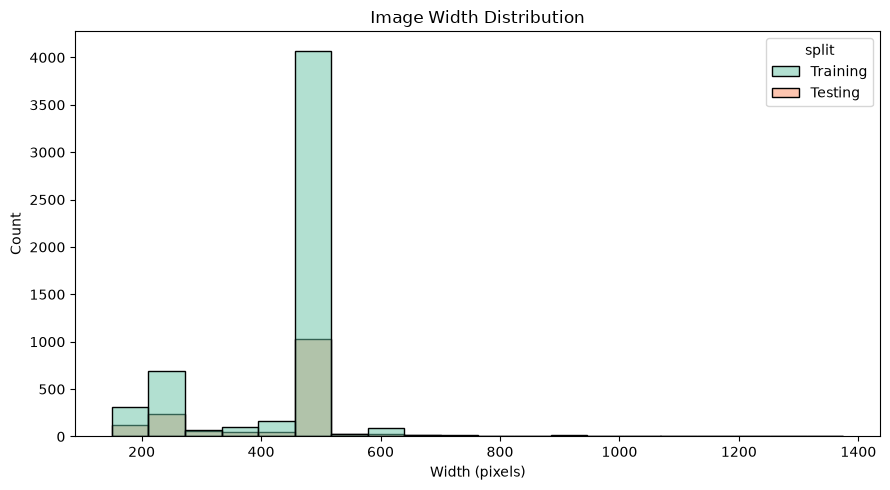

In [27]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="width", hue="split", bins=20, palette="Set2")
plt.title("Image Width Distribution")
plt.xlabel("Width (pixels)")
plt.tight_layout()
plt.show()

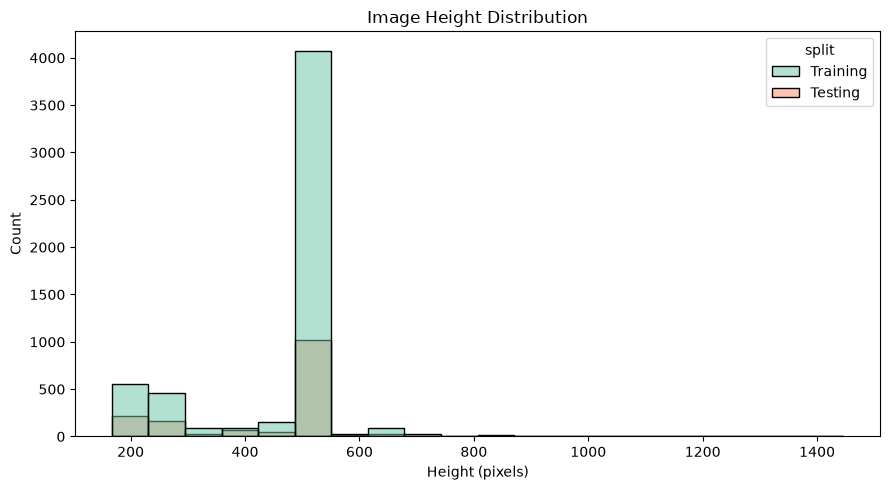

In [31]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="height", hue="split", bins=20, palette="Set2")
plt.title("Image Height Distribution")
plt.xlabel("Height (pixels)")
plt.tight_layout()
plt.show()

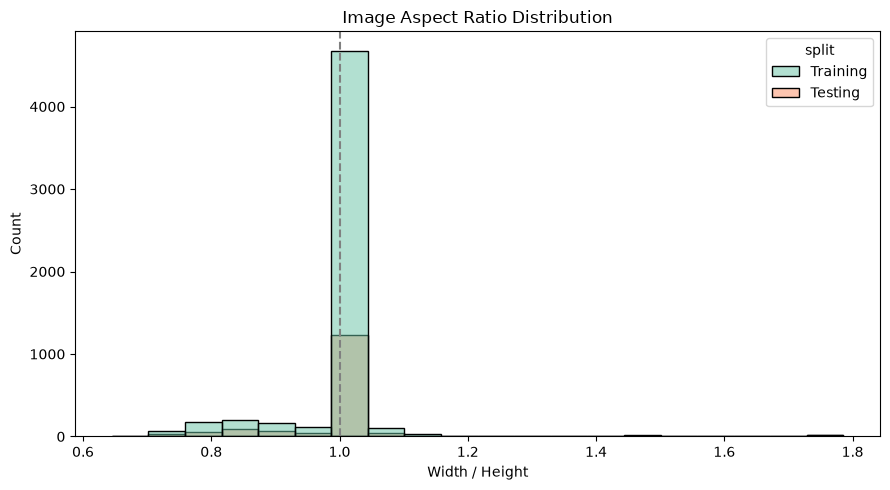

In [29]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="aspect_ratio", hue="split", bins=20, palette="Set2")
plt.axvline(1, linestyle="--", color="gray")
plt.title("Image Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.tight_layout()
plt.show()